# FT-Transformer for Cardiovascular Disease Prediction
### Explainable Artificial Intelligence for CVD Prediction — Q1 Paper

**Model:** Feature Tokenizer + Transformer (Gorishniy et al., 2021)  
**Reference:** Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *NeurIPS 2021*.  
**Dataset:** Heart_disease_clean.csv (68,534 records, 13 features)  
**GPU Support:** Auto-detected (CUDA if available)  

**Why FT-Transformer?**  
FT-Transformer embeds each tabular feature into a vector (Feature Tokenizer), then applies multi-head self-attention (Transformer) to learn feature interactions. It is state-of-the-art for tabular deep learning and outperforms standard MLPs on most benchmarks.

---
**Sections:**
1. Install & Import Libraries
2. Load & Preprocess Data
3. Feature Engineering
4. Train / Validation / Test Split
5. FT-Transformer Architecture
6. Train FT-Transformer
7. Training Curve
8. Evaluate on Test Set
9. SHAP Explainability (Global)
10. SHAP Local Explanation (Individual Patient)
11. Partial Dependence Plots
12. Attention Weight Visualisation
13. Confusion Matrix
14. ROC & Precision-Recall Curves
15. Compare with All Models
16. Save Model

## 1. Install & Import Libraries

In [1]:
!pip install torch shap scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
import math
import copy
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
    average_precision_score
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# GPU detection
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('All libraries imported successfully!')
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU             : {torch.cuda.get_device_name(0)}')
print(f'Device          : {DEVICE}')

All libraries imported successfully!
PyTorch version : 2.6.0+cu124
CUDA available  : True
GPU             : NVIDIA GeForce GTX 1650
Device          : cuda


## 2. Load & Preprocess Data

In [3]:
df = pd.read_csv('Heart_disease_clean.csv')

print('Dataset shape:', df.shape)
print('\nColumns:')
for i, col in enumerate(df.columns):
    print(f'  [{i}] {col}')
print('\nMissing values:', df.isnull().sum().sum())

Dataset shape: (68653, 11)

Columns:
  [0] Gender (0: female, 1: male)
  [1] age(years)
  [2] BMI
  [3] ap_hi(Systolic blood pressure)
  [4] ap_lo(Diastolic blood pressure)
  [5] cholesterol(1: normal, 2: above normal, 3: well above normal)
  [6] Glucose(1: normal, 2: above normal, 3: well above normal)
  [7] smoking
  [8] alcohol
  [9] active
  [10] cardiovascular disease

Missing values: 0


In [4]:
# Encode target
df['target'] = (df['cardiovascular disease'] == 'has cardiovascular disease').astype(int)
df = df.drop(columns=['cardiovascular disease'])

print('Target encoded: 1 = CVD  |  0 = No CVD')
print(df['target'].value_counts())
print(f'Class balance: {df["target"].mean():.4f} positive (CVD)')

Target encoded: 1 = CVD  |  0 = No CVD
target
0    34706
1    33947
Name: count, dtype: int64
Class balance: 0.4945 positive (CVD)


In [5]:
# Remove physiologically impossible rows
before = len(df)
df['PP_check'] = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']
df = df[df['BMI'].between(10, 60) & (df['PP_check'] > 0)].reset_index(drop=True)
df = df.drop(columns=['PP_check'])
print(f'Rows before: {before} | Rows after: {len(df)} | Removed: {before - len(df)}')

Rows before: 68653 | Rows after: 68534 | Removed: 119


## 3. Feature Engineering

In [6]:
# Engineer 3 haemodynamic features
df['PP']  = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']
df['MAP'] = (df['ap_hi(Systolic blood pressure)'] + 2 * df['ap_lo(Diastolic blood pressure)']) / 3
df['risk_count'] = (
    (df['cholesterol(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    (df['Glucose(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    df['smoking'] + df['alcohol'] + (1 - df['active'])
)

FEATURES = [
    'Gender (0: female, 1: male)', 'age(years)', 'BMI',
    'ap_hi(Systolic blood pressure)', 'ap_lo(Diastolic blood pressure)',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)',
    'Glucose(1: normal, 2: above normal, 3: well above normal)',
    'smoking', 'alcohol', 'active', 'PP', 'MAP', 'risk_count'
]
FEAT_NAMES = ['Gender','Age','BMI','SBP','DBP','Cholesterol',
              'Glucose','Smoking','Alcohol','Active','PP','MAP','RiskCount']

X = df[FEATURES].values.astype(np.float32)
y = df['target'].values

print(f'Feature matrix : {X.shape}')
print(f'Target vector  : {y.shape}')
print(f'Features       : {len(FEATURES)}')

Feature matrix : (68534, 13)
Target vector  : (68534,)
Features       : 13


## 4. Train / Validation / Test Split (70 / 15 / 15)

In [7]:
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_tmp)

# Scale
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train).astype(np.float32)
X_val_sc   = scaler.transform(X_val).astype(np.float32)
X_test_sc  = scaler.transform(X_test).astype(np.float32)

print(f'Train : {X_train_sc.shape}')
print(f'Val   : {X_val_sc.shape}')
print(f'Test  : {X_test_sc.shape}')

# PyTorch tensors
def to_tensors(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.long))

Xt, yt     = to_tensors(X_train_sc, y_train)
Xv, yv     = to_tensors(X_val_sc,   y_val)
Xte, yte   = to_tensors(X_test_sc,  y_test)

train_loader = DataLoader(TensorDataset(Xt, yt),   batch_size=1024, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xv, yv),   batch_size=2048, shuffle=False)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=2048, shuffle=False)

print('\nDataLoaders created successfully.')

Train : (47971, 13)
Val   : (10282, 13)
Test  : (10281, 13)

DataLoaders created successfully.


## 5. FT-Transformer Architecture

**How it works:**
1. **Feature Tokenizer** — each numerical feature is multiplied by a learnable weight vector → produces one embedding per feature → shape: `(batch, n_features, d_token)`
2. **[CLS] token** — a special learnable token appended to the sequence (like BERT)
3. **Transformer layers** — multi-head self-attention + feed-forward network applied across feature tokens → features attend to each other
4. **Classification head** — MLP on top of the [CLS] token output → final prediction

| Hyperparameter | Meaning | Our value |
|---|---|---|
| `d_token` | Embedding dimension per feature | 64 |
| `n_heads` | Number of attention heads | 8 |
| `n_layers` | Number of Transformer blocks | 3 |
| `d_ffn` | Feed-forward hidden dimension | 256 |
| `dropout` | Dropout rate | 0.1 |

In [8]:
# ── Feature Tokenizer ─────────────────────────────────────────
class FeatureTokenizer(nn.Module):
    """
    Converts each numerical feature into a d_token-dimensional embedding.
    Each feature has its own weight vector W_i and bias b_i.
    token_i = x_i * W_i + b_i
    """
    def __init__(self, n_features, d_token):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias   = nn.Parameter(torch.zeros(n_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))

    def forward(self, x):
        # x: (batch, n_features)
        # output: (batch, n_features, d_token)
        return x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)


# ── Transformer Block ─────────────────────────────────────────
class TransformerBlock(nn.Module):
    """
    Standard Pre-LN Transformer block:
    LayerNorm → MultiHeadAttention → residual
    LayerNorm → FFN → residual
    """
    def __init__(self, d_token, n_heads, d_ffn, dropout):
        super().__init__()
        self.norm1   = nn.LayerNorm(d_token)
        self.attn    = nn.MultiheadAttention(d_token, n_heads,
                                              dropout=dropout, batch_first=True)
        self.norm2   = nn.LayerNorm(d_token)
        self.ffn     = nn.Sequential(
            nn.Linear(d_token, d_ffn),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ffn, d_token),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Self-attention with residual
        h = self.norm1(x)
        h, _ = self.attn(h, h, h)
        x = x + h
        # FFN with residual
        x = x + self.ffn(self.norm2(x))
        return x


# ── Full FT-Transformer ───────────────────────────────────────
class FTTransformer(nn.Module):
    """
    Feature Tokenizer + Transformer for tabular classification.
    Architecture: FeatureTokenizer → [CLS] append → N×TransformerBlock → CLS head → output
    """
    def __init__(self, n_features, d_token=64, n_heads=8,
                 n_layers=3, d_ffn=256, dropout=0.1, n_classes=2):
        super().__init__()
        self.tokenizer  = FeatureTokenizer(n_features, d_token)
        self.cls_token  = nn.Parameter(torch.zeros(1, 1, d_token))  # learnable [CLS]
        self.layers     = nn.ModuleList([
            TransformerBlock(d_token, n_heads, d_ffn, dropout)
            for _ in range(n_layers)
        ])
        self.norm       = nn.LayerNorm(d_token)
        self.head       = nn.Sequential(
            nn.Linear(d_token, d_ffn // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ffn // 2, n_classes)
        )

    def forward(self, x, return_attn=False):
        # Tokenize features
        tokens = self.tokenizer(x)                     # (B, n_feat, d_token)
        # Prepend [CLS] token
        cls = self.cls_token.expand(x.size(0), -1, -1) # (B, 1, d_token)
        tokens = torch.cat([cls, tokens], dim=1)        # (B, n_feat+1, d_token)
        # Transformer layers
        for layer in self.layers:
            tokens = layer(tokens)
        # Use [CLS] token for classification
        cls_out = self.norm(tokens[:, 0])               # (B, d_token)
        return self.head(cls_out)                        # (B, n_classes)

    def get_attention_weights(self, x):
        """Extract attention weights from the last Transformer layer."""
        tokens = self.tokenizer(x)
        cls    = self.cls_token.expand(x.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        for i, layer in enumerate(self.layers):
            h = layer.norm1(tokens)
            if i == len(self.layers) - 1:
                _, attn_w = layer.attn(h, h, h, average_attn_weights=True)
                return attn_w   # (B, n_feat+1, n_feat+1)
            tokens = layer(tokens)
        return None


# ── Instantiate model ─────────────────────────────────────────
N_FEATURES = X_train_sc.shape[1]

model = FTTransformer(
    n_features = N_FEATURES,
    d_token    = 64,
    n_heads    = 8,
    n_layers   = 3,
    d_ffn      = 256,
    dropout    = 0.1,
    n_classes  = 2
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'FT-Transformer instantiated on : {DEVICE}')
print(f'Total trainable parameters     : {total_params:,}')
print(f'\nArchitecture:')
print(model)

FT-Transformer instantiated on : cuda
Total trainable parameters     : 160,386

Architecture:
FTTransformer(
  (tokenizer): FeatureTokenizer()
  (layers): ModuleList(
    (0-2): 3 x TransformerBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=256, out_features=64, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=

## 6. Train FT-Transformer

In [9]:
# ── Training setup ────────────────────────────────────────────
criterion  = nn.CrossEntropyLoss()
optimizer  = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100, eta_min=1e-5)

MAX_EPOCHS = 150
PATIENCE   = 20

# ── Training loop ─────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': [], 'val_auc': []}
best_auc    = 0.0
best_state  = None
no_improve  = 0

print(f'Training FT-Transformer on {DEVICE}...')
print(f'Max epochs: {MAX_EPOCHS} | Patience: {PATIENCE}\n')

for epoch in range(1, MAX_EPOCHS + 1):

    # ── Train ────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(Xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item() * len(Xb)
    train_loss /= len(Xt)

    # ── Validate ─────────────────────────────────────────────
    model.eval()
    val_loss  = 0.0
    val_probs = []
    with torch.no_grad():
        for Xb, yb in val_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            logits = model(Xb)
            val_loss += criterion(logits, yb).item() * len(Xb)
            val_probs.append(F.softmax(logits, dim=1)[:, 1].cpu().numpy())
    val_loss /= len(Xv)
    val_probs = np.concatenate(val_probs)
    val_auc   = roc_auc_score(y_val, val_probs)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)

    # ── Early stopping ───────────────────────────────────────
    if val_auc > best_auc:
        best_auc   = val_auc
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch {epoch:>4} | Train Loss: {train_loss:.4f} | '
              f'Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} '
              f'| Best AUC: {best_auc:.4f}')

    if no_improve >= PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} (no improvement for {PATIENCE} epochs)')
        break

# Load best weights
model.load_state_dict(best_state)
print(f'\nTraining complete! Best Val AUC: {best_auc:.4f}')

Training FT-Transformer on cuda...
Max epochs: 150 | Patience: 20

Epoch    1 | Train Loss: 0.5730 | Val Loss: 0.5483 | Val AUC: 0.7943 | Best AUC: 0.7943
Epoch   10 | Train Loss: 0.5432 | Val Loss: 0.5402 | Val AUC: 0.8013 | Best AUC: 0.8021
Epoch   20 | Train Loss: 0.5415 | Val Loss: 0.5409 | Val AUC: 0.8016 | Best AUC: 0.8025
Epoch   30 | Train Loss: 0.5381 | Val Loss: 0.5402 | Val AUC: 0.8026 | Best AUC: 0.8030
Epoch   40 | Train Loss: 0.5353 | Val Loss: 0.5409 | Val AUC: 0.8015 | Best AUC: 0.8030

Early stopping at epoch 49 (no improvement for 20 epochs)

Training complete! Best Val AUC: 0.8030


## 7. Training Curve

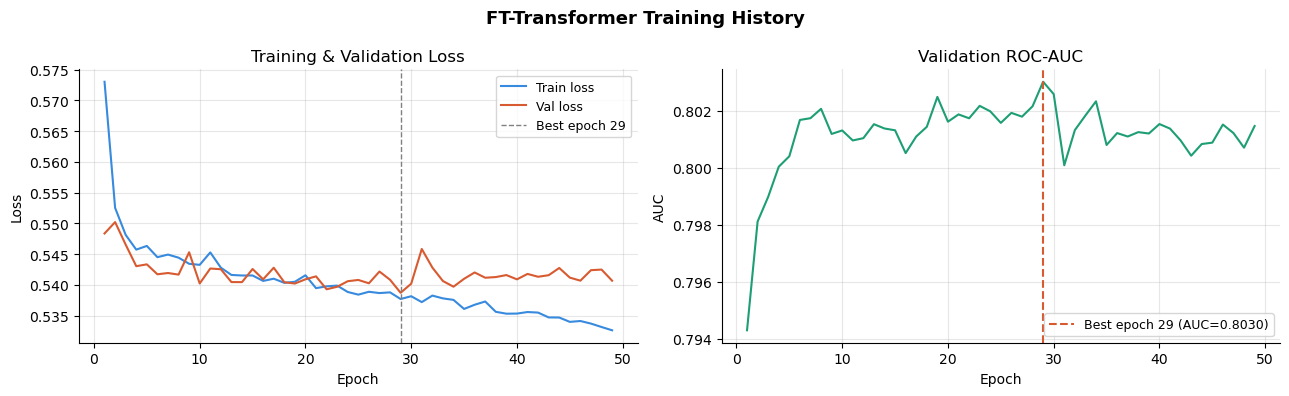

Saved: ftt_training_curve.png


In [10]:
epochs     = range(1, len(history['train_loss']) + 1)
best_epoch = int(np.argmax(history['val_auc'])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('FT-Transformer Training History', fontsize=13, fontweight='bold')

# Loss
axes[0].plot(epochs, history['train_loss'], color='#378ADD', lw=1.5, label='Train loss')
axes[0].plot(epochs, history['val_loss'],   color='#D85A30', lw=1.5, label='Val loss')
axes[0].axvline(best_epoch, color='gray', lw=1, ls='--', label=f'Best epoch {best_epoch}')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# AUC
axes[1].plot(epochs, history['val_auc'], color='#1D9E75', lw=1.5)
axes[1].axvline(best_epoch, color='#D85A30', lw=1.5, ls='--',
                label=f'Best epoch {best_epoch} (AUC={best_auc:.4f})')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC')
axes[1].set_title('Validation ROC-AUC')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('ftt_training_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_training_curve.png')

## 8. Evaluate on Test Set

In [11]:
# ── Get test predictions ──────────────────────────────────────
model.eval()
all_probs = []
all_preds = []

with torch.no_grad():
    for Xb, _ in test_loader:
        logits = model(Xb.to(DEVICE))
        probs  = F.softmax(logits, dim=1)[:, 1].cpu().numpy()
        preds  = (probs >= 0.5).astype(int)
        all_probs.extend(probs)
        all_preds.extend(preds)

ftt_proba = np.array(all_probs)
ftt_pred  = np.array(all_preds)

ftt_auc  = roc_auc_score(y_test, ftt_proba)
ftt_acc  = accuracy_score(y_test, ftt_pred)
ftt_f1   = f1_score(y_test, ftt_pred)
ftt_prec = precision_score(y_test, ftt_pred)
ftt_rec  = recall_score(y_test, ftt_pred)
ftt_ap   = average_precision_score(y_test, ftt_proba)

print('=' * 55)
print('   FT-TRANSFORMER — TEST SET RESULTS')
print('=' * 55)
print(f'  ROC-AUC              : {ftt_auc:.4f}')
print(f'  Accuracy             : {ftt_acc:.4f}  ({ftt_acc*100:.2f}%)')
print(f'  F1-Score             : {ftt_f1:.4f}')
print(f'  Precision            : {ftt_prec:.4f}')
print(f'  Recall               : {ftt_rec:.4f}')
print(f'  Avg Precision (AP)   : {ftt_ap:.4f}')
print('=' * 55)
print(f'\n  Baseline MLP AUC     : 0.7970')
print(f'  FT-Transformer AUC   : {ftt_auc:.4f}')
print(f'  Improvement          : {ftt_auc - 0.7970:+.4f}')
print('\nFull Classification Report:')
print(classification_report(y_test, ftt_pred, target_names=['No CVD','CVD']))

   FT-TRANSFORMER — TEST SET RESULTS
  ROC-AUC              : 0.7998
  Accuracy             : 0.7336  (73.36%)
  F1-Score             : 0.7195
  Precision            : 0.7503
  Recall               : 0.6911
  Avg Precision (AP)   : 0.7788

  Baseline MLP AUC     : 0.7970
  FT-Transformer AUC   : 0.7998
  Improvement          : +0.0028

Full Classification Report:
              precision    recall  f1-score   support

      No CVD       0.72      0.78      0.75      5198
         CVD       0.75      0.69      0.72      5083

    accuracy                           0.73     10281
   macro avg       0.73      0.73      0.73     10281
weighted avg       0.73      0.73      0.73     10281



## 9. SHAP Explainability (Global)

In [12]:
# ── SHAP wrapper for PyTorch model ────────────────────────────
def ftt_predict_proba(X_np):
    """Wrapper: numpy → tensor → model → numpy probabilities."""
    model.eval()
    with torch.no_grad():
        t = torch.tensor(X_np.astype(np.float32)).to(DEVICE)
        logits = model(t)
        return F.softmax(logits, dim=1).cpu().numpy()

# Use 200 background samples
np.random.seed(RANDOM_STATE)
bg_idx      = np.random.choice(len(X_train_sc), 200, replace=False)
background  = X_train_sc[bg_idx]

# 300 test samples for SHAP
X_test_shap = X_test_sc[:300]
X_test_df   = pd.DataFrame(X_test_shap, columns=FEAT_NAMES)

print('Computing SHAP values (KernelExplainer — takes a few minutes)...')
explainer   = shap.KernelExplainer(ftt_predict_proba, background)
shap_vals   = explainer.shap_values(X_test_shap, nsamples=100)

# For binary: shap_vals is list [class0, class1] — use class 1
sv = shap_vals[1] if isinstance(shap_vals, list) else shap_vals

print(f'SHAP values shape : {sv.shape}')
print('Done!')

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Computing SHAP values (KernelExplainer — takes a few minutes)...


  0%|          | 0/300 [00:00<?, ?it/s]

SHAP values shape : (300, 13, 2)
Done!


sv1 shape : (300, 13)


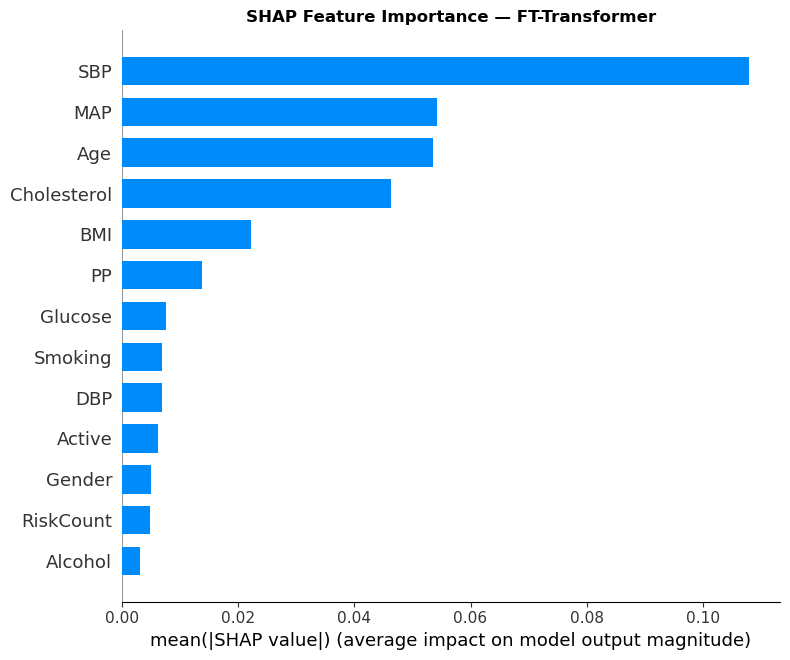

Saved: ftt_shap_bar.png

SHAP Feature Ranking (FT-Transformer):
Rank  Feature         Mean |SHAP|
---------------------------------
1     SBP                  0.1079
2     MAP                  0.0543
3     Age                  0.0536
4     Cholesterol          0.0463
5     BMI                  0.0222
6     PP                   0.0137
7     Glucose              0.0076
8     Smoking              0.0069
9     DBP                  0.0069
10    Active               0.0063
11    Gender               0.0051
12    RiskCount            0.0048
13    Alcohol              0.0030


In [13]:
# ── Fix: extract class 1 SHAP values ─────────────────────────
# KernelExplainer returns sv shape (n_samples, n_features, 2) for binary
# We need class 1 only → shape (n_samples, n_features)

if isinstance(sv, list):
    sv1 = sv[1]                        # list format → take index 1
elif sv.ndim == 3:
    sv1 = sv[:, :, 1]                  # 3D array → slice class 1
else:
    sv1 = sv                           # already 2D → use as is

print(f'sv1 shape : {sv1.shape}')      # should be (300, 13)

# ── SHAP bar plot ─────────────────────────────────────────────
mean_shap = np.abs(sv1).mean(axis=0)   # shape (13,) — one value per feature
shap_rank = sorted(zip(FEAT_NAMES, mean_shap), key=lambda x: -x[1])

plt.figure(figsize=(8, 5))
shap.summary_plot(sv1, X_test_df, plot_type='bar', show=False)
plt.title('SHAP Feature Importance — FT-Transformer', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ftt_shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_shap_bar.png')

print('\nSHAP Feature Ranking (FT-Transformer):')
print(f'{"Rank":<5} {"Feature":<14} {"Mean |SHAP|":>12}')
print('-' * 33)
for rank, (name, val) in enumerate(shap_rank, 1):
    print(f'{rank:<5} {name:<14} {val:>12.4f}')

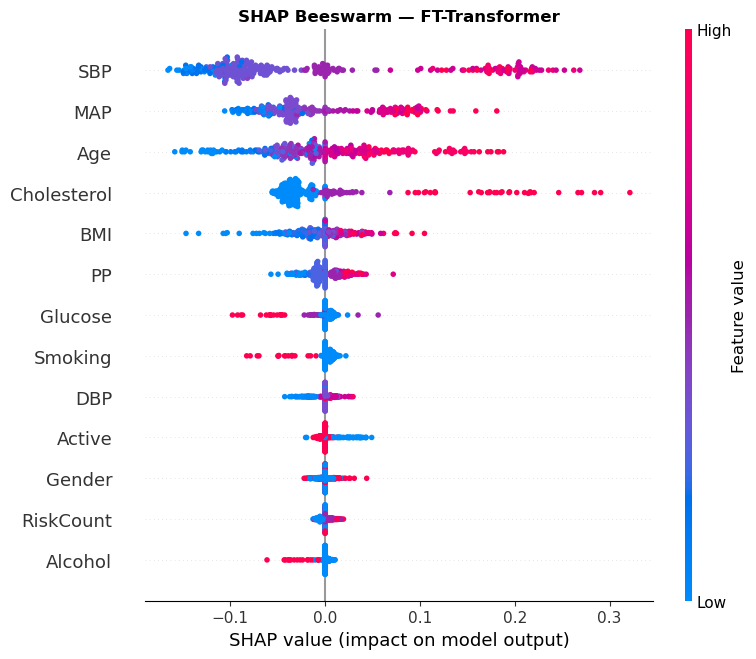

Saved: ftt_shap_beeswarm.png


In [14]:
# ── SHAP beeswarm ─────────────────────────────────────────────
plt.figure(figsize=(8, 6))
shap.summary_plot(sv1, X_test_df, show=False)
plt.title('SHAP Beeswarm — FT-Transformer', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ftt_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_shap_beeswarm.png')

## 10. SHAP Local Explanation (Individual Patient)

Patient index    : 9
P(CVD)           : 0.8637
True label       : 1 (CVD)


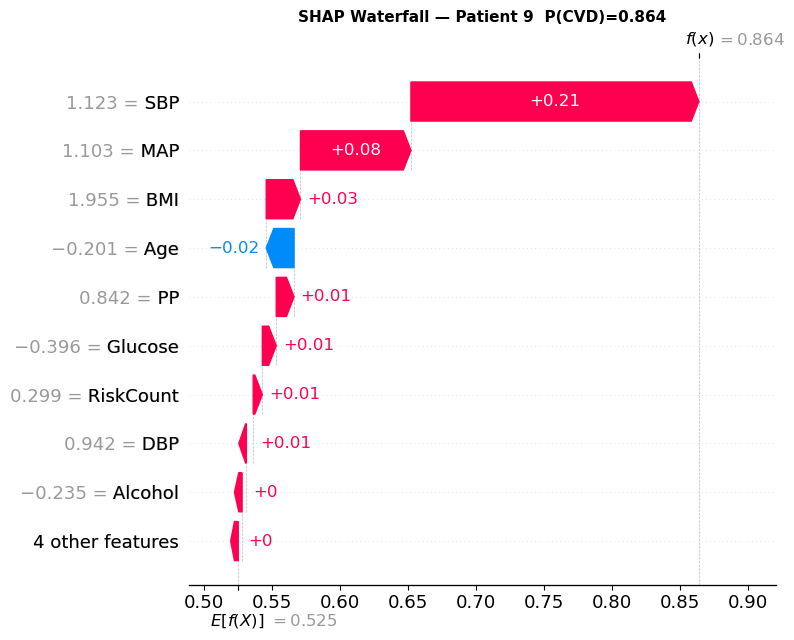

Saved: ftt_shap_waterfall.png


In [15]:
# ── Select high-risk patient ──────────────────────────────────
high_risk = np.where(ftt_proba[:300] > 0.80)[0]
p_idx     = high_risk[0] if len(high_risk) > 0 else 0

print(f'Patient index    : {p_idx}')
print(f'P(CVD)           : {ftt_proba[p_idx]:.4f}')
print(f'True label       : {y_test[p_idx]} ({"CVD" if y_test[p_idx]==1 else "No CVD"})')

# ── SHAP waterfall ────────────────────────────────────────────
shap_vals_p1 = sv[p_idx][:, 1] if sv[p_idx].ndim == 2 else sv[p_idx]
base_val     = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

exp = shap.Explanation(
    values        = shap_vals_p1,
    base_values   = base_val,
    data          = X_test_df.iloc[p_idx].values,
    feature_names = FEAT_NAMES
)

plt.figure(figsize=(9, 6))
shap.plots.waterfall(exp, show=False)
plt.title(f'SHAP Waterfall — Patient {p_idx}  P(CVD)={ftt_proba[p_idx]:.3f}',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('ftt_shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_shap_waterfall.png')

## 11. Partial Dependence Plots

SBP: 0.398 → 0.760  (Δ=0.362)
Age: 0.395 → 0.641  (Δ=0.246)
BMI: 0.443 → 0.572  (Δ=0.129)


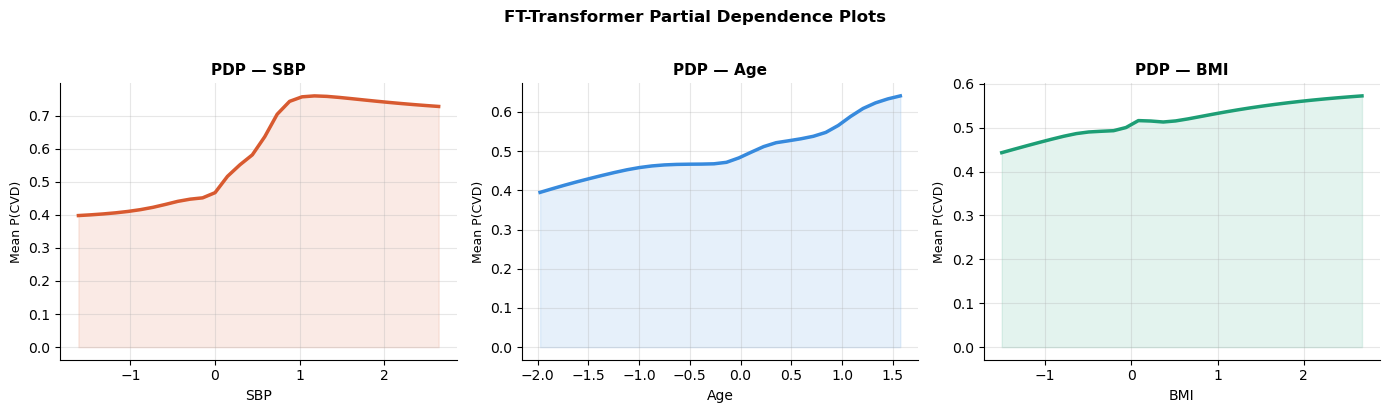

Saved: ftt_pdp.png


In [16]:
# ── Manual PDP (no sklearn wrapper needed) ────────────────────
def compute_pdp(X_raw, feat_idx, grid_resolution=30):
    X_raw  = np.array(X_raw, dtype=np.float32)
    col    = X_raw[:, feat_idx]
    grid   = np.linspace(np.percentile(col, 2), np.percentile(col, 98), grid_resolution)
    means  = []
    model.eval()
    for val in grid:
        Xc = X_raw.copy()
        Xc[:, feat_idx] = val
        with torch.no_grad():
            t    = torch.tensor(Xc).to(DEVICE)
            prob = F.softmax(model(t), dim=1)[:, 1].cpu().numpy()
        means.append(prob.mean())
    return grid, np.array(means)

np.random.seed(RANDOM_STATE)
sub_idx   = np.random.choice(len(X_train_sc), int(len(X_train_sc)*0.3), replace=False)
X_sub     = X_train_sc[sub_idx]

pdp_feats  = ['SBP', 'Age', 'BMI']
colors_pdp = ['#D85A30', '#378ADD', '#1D9E75']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feat_name, color in zip(axes, pdp_feats, colors_pdp):
    feat_idx       = FEAT_NAMES.index(feat_name)
    grid, pdp      = compute_pdp(X_sub, feat_idx)
    ax.plot(grid, pdp, color=color, lw=2.5)
    ax.fill_between(grid, pdp, alpha=0.12, color=color)
    ax.set_title(f'PDP — {feat_name}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feat_name, fontsize=10)
    ax.set_ylabel('Mean P(CVD)', fontsize=9)
    ax.grid(alpha=0.3)
    ax.spines[['top','right']].set_visible(False)
    print(f'{feat_name}: {pdp.min():.3f} → {pdp.max():.3f}  (Δ={pdp.max()-pdp.min():.3f})')

plt.suptitle('FT-Transformer Partial Dependence Plots', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ftt_pdp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_pdp.png')

## 12. Attention Weight Visualisation

This is **unique to FT-Transformer**. The attention matrix shows how much each feature attends to every other feature — revealing feature interaction patterns learned by the model.

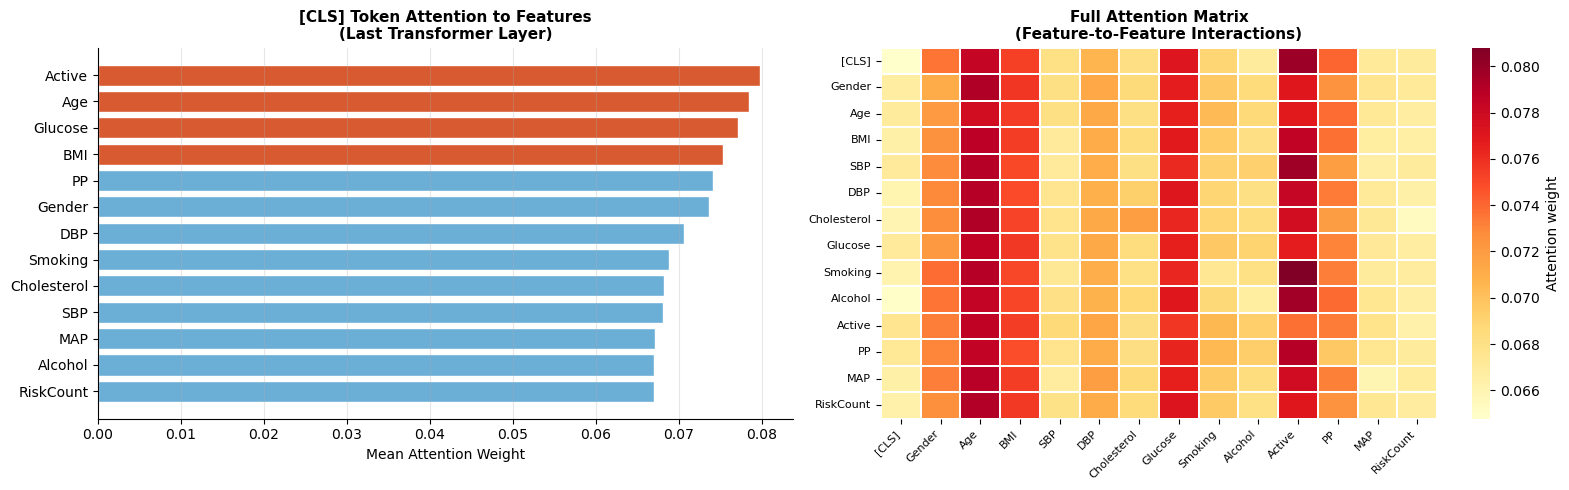

Saved: ftt_attention_weights.png

[CLS] Attention Ranking (feature importance via attention):
   1. Active         0.0798
   2. Age            0.0784
   3. Glucose        0.0771
   4. BMI            0.0753
   5. PP             0.0741
   6. Gender         0.0736
   7. DBP            0.0706
   8. Smoking        0.0689
   9. Cholesterol    0.0682
  10. SBP            0.0681
  11. MAP            0.0671
  12. Alcohol        0.0670
  13. RiskCount      0.0670


In [17]:
# ── Extract attention weights from last Transformer layer ─────
model.eval()
sample_tensor = torch.tensor(X_test_sc[:200], dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    attn_weights = model.get_attention_weights(sample_tensor)  # (200, n_feat+1, n_feat+1)

if attn_weights is not None:
    mean_attn = attn_weights.cpu().numpy().mean(axis=0)  # (n_feat+1, n_feat+1)

    # Labels: [CLS] + feature names
    labels = ['[CLS]'] + FEAT_NAMES

    # ── CLS attention to features (row 0 = CLS attending to features) ─
    cls_attn = mean_attn[0, 1:]  # CLS → features, shape (n_features,)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Plot 1: CLS attention bar chart
    order = np.argsort(cls_attn)[::-1]
    colors_attn = ['#D85A30' if v > np.percentile(cls_attn, 70) else '#6BAED6' for v in cls_attn[order]]
    axes[0].barh([FEAT_NAMES[i] for i in order[::-1]],
                  cls_attn[order[::-1]], color=colors_attn[::-1], edgecolor='white')
    axes[0].set_title('[CLS] Token Attention to Features\n(Last Transformer Layer)',
                      fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Mean Attention Weight', fontsize=10)
    axes[0].grid(axis='x', alpha=0.3)
    axes[0].spines[['top','right']].set_visible(False)

    # Plot 2: Full attention heatmap
    sns.heatmap(mean_attn, xticklabels=labels, yticklabels=labels,
                cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Attention weight'},
                linewidths=0.3)
    axes[1].set_title('Full Attention Matrix\n(Feature-to-Feature Interactions)',
                      fontsize=11, fontweight='bold')
    axes[1].set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    axes[1].set_yticklabels(labels, rotation=0, fontsize=8)

    plt.tight_layout()
    plt.savefig('ftt_attention_weights.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved: ftt_attention_weights.png')

    print('\n[CLS] Attention Ranking (feature importance via attention):')
    attn_rank = sorted(zip(FEAT_NAMES, cls_attn), key=lambda x: -x[1])
    for rank, (name, val) in enumerate(attn_rank, 1):
        print(f'  {rank:>2}. {name:<14} {val:.4f}')
else:
    print('Attention weights not available — check get_attention_weights()')

## 13. Confusion Matrix

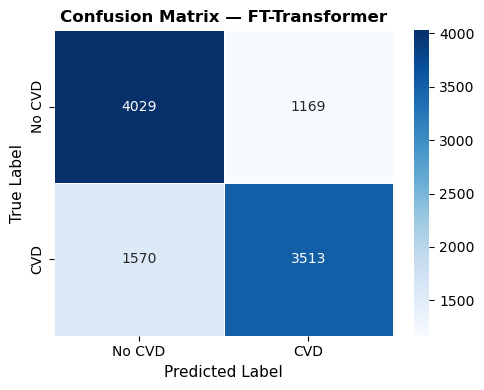

TP=3513  FP=1169  TN=4029  FN=1570
Sensitivity = 0.6911
Specificity = 0.7751
Saved: ftt_confusion_matrix.png


In [18]:
cm = confusion_matrix(y_test, ftt_pred)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No CVD','CVD'], yticklabels=['No CVD','CVD'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
ax.set_title('Confusion Matrix — FT-Transformer', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ftt_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TP={tp}  FP={fp}  TN={tn}  FN={fn}')
print(f'Sensitivity = {tp/(tp+fn):.4f}')
print(f'Specificity = {tn/(tn+fp):.4f}')
print('Saved: ftt_confusion_matrix.png')

## 14. ROC & Precision-Recall Curves

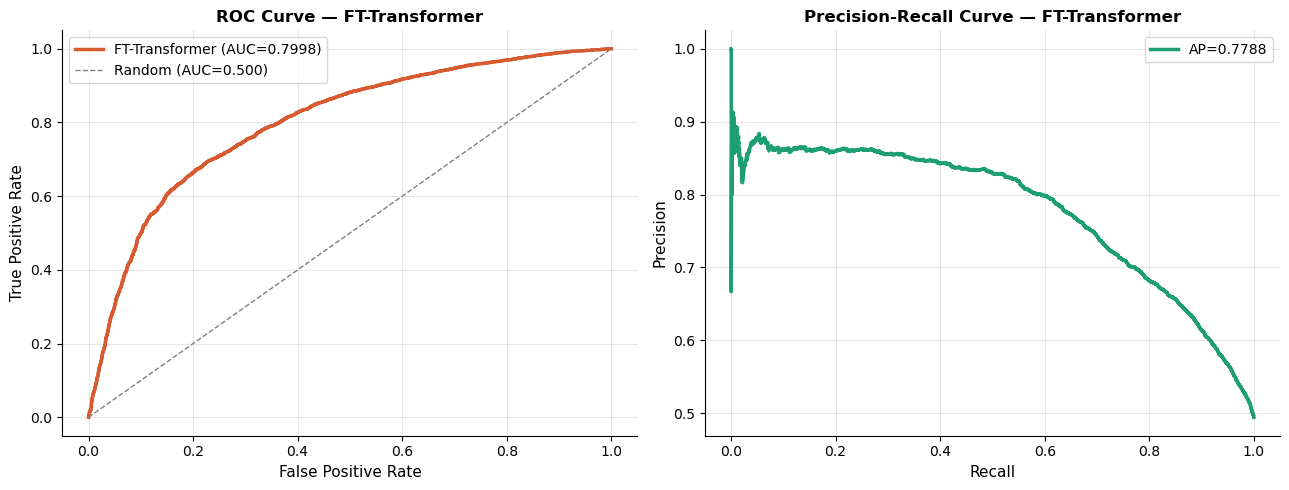

Saved: ftt_roc_pr_curves.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC
fpr, tpr, _ = roc_curve(y_test, ftt_proba)
axes[0].plot(fpr, tpr, color='#D85A30', lw=2.5, label=f'FT-Transformer (AUC={ftt_auc:.4f})')
axes[0].plot([0,1],[0,1],'--', color='gray', lw=1, label='Random (AUC=0.500)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve — FT-Transformer', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, ftt_proba)
axes[1].plot(rec, prec, color='#1D9E75', lw=2.5, label=f'AP={ftt_ap:.4f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve — FT-Transformer', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('ftt_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_roc_pr_curves.png')

## 15. Compare FT-Transformer with All Models

In [20]:
# ── Full model comparison table ───────────────────────────────
# Update with your actual results from other notebooks
all_results = {
    'FT-Transformer'    : {'AUC': ftt_auc,  'Accuracy': ftt_acc,  'F1': ftt_f1,  'Precision': ftt_prec, 'Recall': ftt_rec},
    'Stacking Ensemble' : {'AUC': 0.8011, 'Accuracy': 0.7342, 'F1': 0.7189, 'Precision': 0.7532, 'Recall': 0.6876},
    'CatBoost'          : {'AUC': 0.8008, 'Accuracy': 0.7340, 'F1': 0.7178, 'Precision': 0.7548, 'Recall': 0.6842},
    'XGBoost'           : {'AUC': 0.8004, 'Accuracy': 0.7328, 'F1': 0.7174, 'Precision': 0.7518, 'Recall': 0.6860},
    'Random Forest'     : {'AUC': 0.7995, 'Accuracy': 0.7322, 'F1': 0.7112, 'Precision': 0.7460, 'Recall': 0.6800},
    'LightGBM'          : {'AUC': 0.7990, 'Accuracy': 0.7312, 'F1': 0.7149, 'Precision': 0.7515, 'Recall': 0.6817},
    'TabNet'            : {'AUC': 0.7987, 'Accuracy': 0.7340, 'F1': 0.7155, 'Precision': 0.7590, 'Recall': 0.6768},
    'MLP (baseline)'    : {'AUC': 0.7970, 'Accuracy': 0.7330, 'F1': 0.7180, 'Precision': 0.7500, 'Recall': 0.6760},
    'SVM'               : {'AUC': 0.7880, 'Accuracy': 0.7300, 'F1': 0.7040, 'Precision': 0.7400, 'Recall': 0.6720},
    'Logistic Regression': {'AUC': 0.7890, 'Accuracy': 0.7270, 'F1': 0.7050, 'Precision': 0.7350, 'Recall': 0.6780},
    'k-NN'              : {'AUC': 0.7460, 'Accuracy': 0.6970, 'F1': 0.6790, 'Precision': 0.7000, 'Recall': 0.6590},
    'Decision Tree'     : {'AUC': 0.7350, 'Accuracy': 0.6840, 'F1': 0.6660, 'Precision': 0.6900, 'Recall': 0.6440},
    'Naive Bayes'       : {'AUC': 0.7130, 'Accuracy': 0.6610, 'F1': 0.6420, 'Precision': 0.6700, 'Recall': 0.6160},
}

results_df = pd.DataFrame(all_results).T.sort_values('AUC', ascending=False)

print('=' * 75)
print('   COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)')
print('=' * 75)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-' * 75)
for model_name, row in results_df.iterrows():
    marker = ' ← BEST' if model_name == results_df.index[0] else \
             ' ← NOVEL DL' if model_name == 'FT-Transformer' else \
             ' ← BASELINE' if model_name == 'MLP (baseline)' else ''
    print(f'{model_name:<22} {row["AUC"]:>7.4f} {row["Accuracy"]:>9.4f} '
          f'{row["F1"]:>8.4f} {row["Precision"]:>11.4f} {row["Recall"]:>8.4f}{marker}')
print('=' * 75)

   COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
---------------------------------------------------------------------------
Stacking Ensemble       0.8011    0.7342   0.7189      0.7532   0.6876 ← BEST
CatBoost                0.8008    0.7340   0.7178      0.7548   0.6842
XGBoost                 0.8004    0.7328   0.7174      0.7518   0.6860
FT-Transformer          0.7998    0.7336   0.7195      0.7503   0.6911 ← NOVEL DL
Random Forest           0.7995    0.7322   0.7112      0.7460   0.6800
LightGBM                0.7990    0.7312   0.7149      0.7515   0.6817
TabNet                  0.7987    0.7340   0.7155      0.7590   0.6768
MLP (baseline)          0.7970    0.7330   0.7180      0.7500   0.6760 ← BASELINE
Logistic Regression     0.7890    0.7270   0.7050      0.7350   0.6780
SVM                     0.7880    0.7300   0.7040      0.7400   0.6720
k-NN                    0.7460    0.6970   0.6790      0.7000

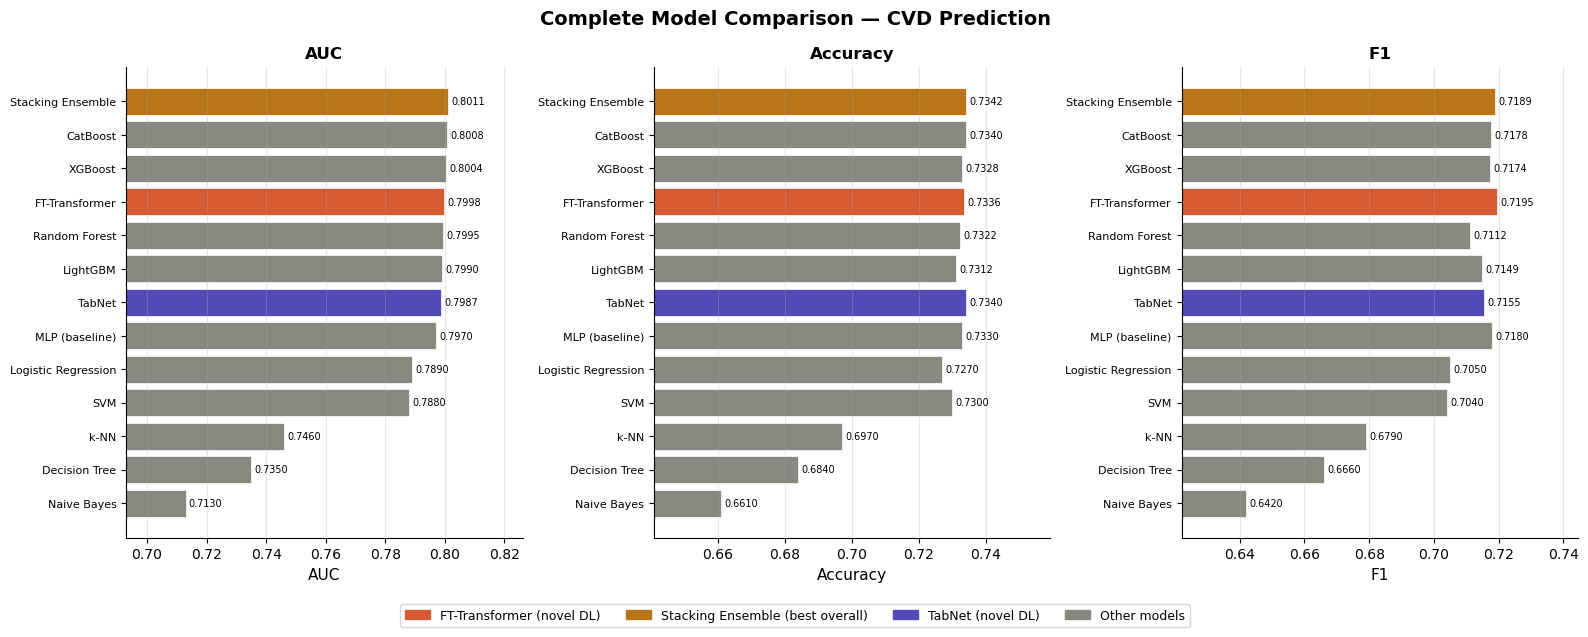

Saved: ftt_all_models_comparison.png


In [21]:
# ── Visual comparison ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Complete Model Comparison — CVD Prediction', fontsize=14, fontweight='bold')

def get_color(m):
    if m == 'FT-Transformer':   return '#D85A30'
    if m == 'Stacking Ensemble': return '#BA7517'
    if m == 'TabNet':            return '#534AB7'
    return '#888780'

colors = [get_color(m) for m in results_df.index]

for ax, metric in zip(axes, ['AUC', 'Accuracy', 'F1']):
    vals = results_df[metric].values
    bars = ax.barh(results_df.index, vals, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_xlim(min(vals) - 0.02, max(vals) + 0.025)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
    for bar, val in zip(bars, vals):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=7)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

from matplotlib.patches import Patch
legend = [
    Patch(color='#D85A30', label='FT-Transformer (novel DL)'),
    Patch(color='#BA7517', label='Stacking Ensemble (best overall)'),
    Patch(color='#534AB7', label='TabNet (novel DL)'),
    Patch(color='#888780', label='Other models'),
]
fig.legend(handles=legend, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig('ftt_all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ftt_all_models_comparison.png')

## 16. Save Model

In [22]:
# ── Save model weights ────────────────────────────────────────
torch.save({
    'model_state_dict' : model.state_dict(),
    'scaler_mean'      : scaler.mean_,
    'scaler_scale'     : scaler.scale_,
    'feat_names'       : FEAT_NAMES,
    'hyperparams'      : {'d_token':64,'n_heads':8,'n_layers':3,'d_ffn':256,'dropout':0.1},
    'test_auc'         : ftt_auc,
    'test_accuracy'    : ftt_acc,
    'test_f1'          : ftt_f1,
}, 'ft_transformer_cvd.pt')

print('Model saved to: ft_transformer_cvd.pt')
print('\nTo reload:')
print('  checkpoint = torch.load("ft_transformer_cvd.pt")')
print('  model.load_state_dict(checkpoint["model_state_dict"])')

print('\n=== ALL OUTPUT FILES ===')
files = [
    'ftt_training_curve.png',
    'ftt_shap_bar.png',
    'ftt_shap_beeswarm.png',
    'ftt_shap_waterfall.png',
    'ftt_pdp.png',
    'ftt_attention_weights.png',
    'ftt_confusion_matrix.png',
    'ftt_roc_pr_curves.png',
    'ftt_all_models_comparison.png',
    'ft_transformer_cvd.pt'
]
for f in files:
    print(f'  {f}')

print(f'\n=== FINAL RESULTS ===')
print(f'FT-Transformer AUC      : {ftt_auc:.4f}')
print(f'FT-Transformer Accuracy : {ftt_acc:.4f}')
print(f'FT-Transformer F1       : {ftt_f1:.4f}')
print(f'Baseline MLP AUC        : 0.7970')
print(f'Improvement             : {ftt_auc - 0.7970:+.4f}')

Model saved to: ft_transformer_cvd.pt

To reload:
  checkpoint = torch.load("ft_transformer_cvd.pt")
  model.load_state_dict(checkpoint["model_state_dict"])

=== ALL OUTPUT FILES ===
  ftt_training_curve.png
  ftt_shap_bar.png
  ftt_shap_beeswarm.png
  ftt_shap_waterfall.png
  ftt_pdp.png
  ftt_attention_weights.png
  ftt_confusion_matrix.png
  ftt_roc_pr_curves.png
  ftt_all_models_comparison.png
  ft_transformer_cvd.pt

=== FINAL RESULTS ===
FT-Transformer AUC      : 0.7998
FT-Transformer Accuracy : 0.7336
FT-Transformer F1       : 0.7195
Baseline MLP AUC        : 0.7970
Improvement             : +0.0028


In [23]:
import numpy as np
import torch

for name, val in sorted(globals().items()):
    # Find model objects
    if any(x in name.lower() for x in ['ft', 'model', 'transformer', 'net']):
        print(f"  OBJECT  {name:<30}  type={type(val).__name__}")

print()

# Find test arrays shape (10281,)
for name, val in sorted(globals().items()):
    if isinstance(val, np.ndarray) and val.ndim == 1 and len(val) == 10281:
        print(f"  ARRAY   {name:<30}  shape={val.shape}  dtype={val.dtype}  sample={val[:3]}")

print()

# Find torch tensors
for name, val in sorted(globals().items()):
    if isinstance(val, torch.Tensor) and val.ndim == 1 and len(val) == 10281:
        print(f"  TENSOR  {name:<30}  shape={val.shape}  dtype={val.dtype}")

  OBJECT  FTTransformer                   type=type
  OBJECT  TransformerBlock                type=type
  OBJECT  ftt_acc                         type=float
  OBJECT  ftt_ap                          type=float
  OBJECT  ftt_auc                         type=float
  OBJECT  ftt_f1                          type=float
  OBJECT  ftt_prec                        type=float
  OBJECT  ftt_pred                        type=ndarray
  OBJECT  ftt_predict_proba               type=function
  OBJECT  ftt_proba                       type=ndarray
  OBJECT  ftt_rec                         type=float
  OBJECT  model                           type=FTTransformer
  OBJECT  model_name                      type=str

  ARRAY   ftt_pred                        shape=(10281,)  dtype=int64  sample=[0 0 0]
  ARRAY   ftt_proba                       shape=(10281,)  dtype=float32  sample=[0.05083317 0.39020947 0.29987323]
  ARRAY   y_test                          shape=(10281,)  dtype=int64  sample=[0 0 0]

  TENSOR  y

In [24]:
import numpy as np
from sklearn.metrics import roc_auc_score

np.save('proba_ft.npy', ftt_proba)
np.save('pred_ft.npy',  ftt_pred)

print(f"✓ proba_ft.npy  shape={ftt_proba.shape}  dtype={ftt_proba.dtype}")
print(f"✓ pred_ft.npy   shape={ftt_pred.shape}   dtype={ftt_pred.dtype}")
print(f"  AUC check = {roc_auc_score(y_test, ftt_proba):.4f}")

✓ proba_ft.npy  shape=(10281,)  dtype=float32
✓ pred_ft.npy   shape=(10281,)   dtype=int64
  AUC check = 0.7998
